## Етап 1. Графік порожньої коробки

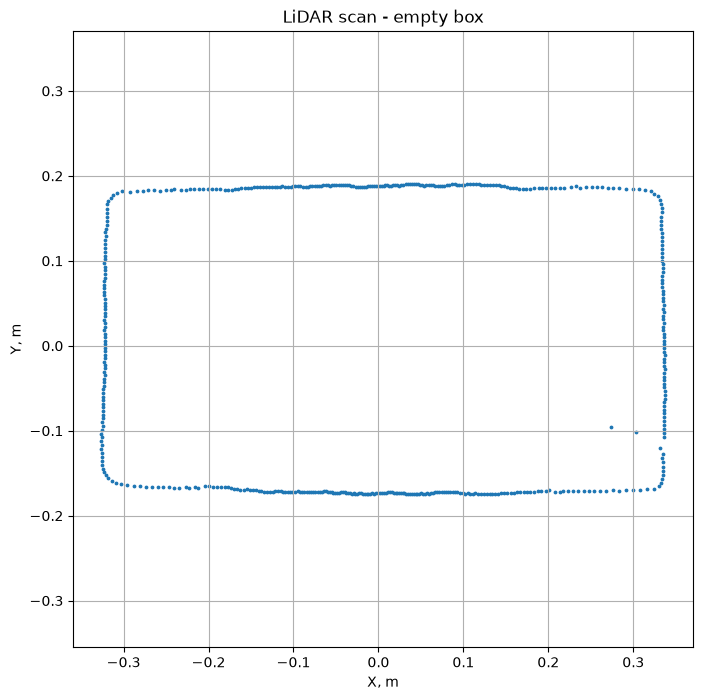

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

file_path = Path('data') / 'scan_20261106_103616.csv'

data = pd.read_csv(file_path)

scan = data[data['scan'] == 0].copy()

angles = np.radians(scan['angle_deg'].to_numpy())

distances = scan['dist_mm'].to_numpy() / 1000

x = distances * np.sin(angles)
y = distances * np.cos(angles)

plt.figure(figsize=(8, 8))
plt.scatter(x, y, s=3)

plt.title('LiDAR scan - empty box')
plt.xlabel('X, m')
plt.ylabel('Y, m')

plt.axis('equal')
plt.grid(True)

plt.show()

## Етап 3

[PosixPath('data/scan_20261107_172450.csv'), PosixPath('data/scan_20261106_103616.csv')]
Кількість точок: 504


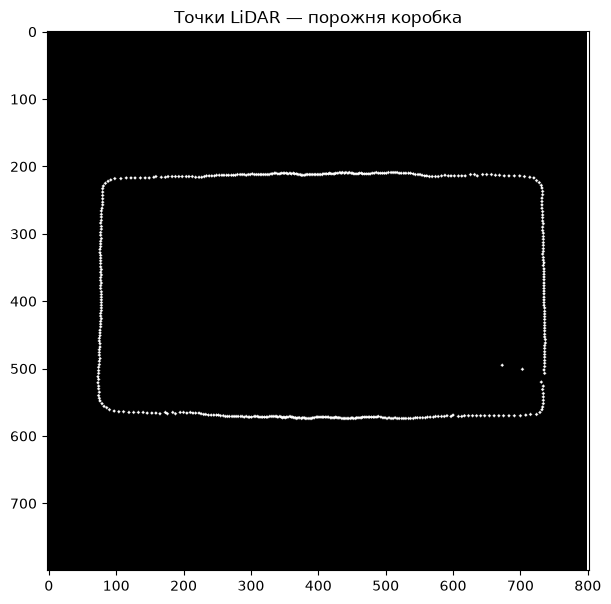

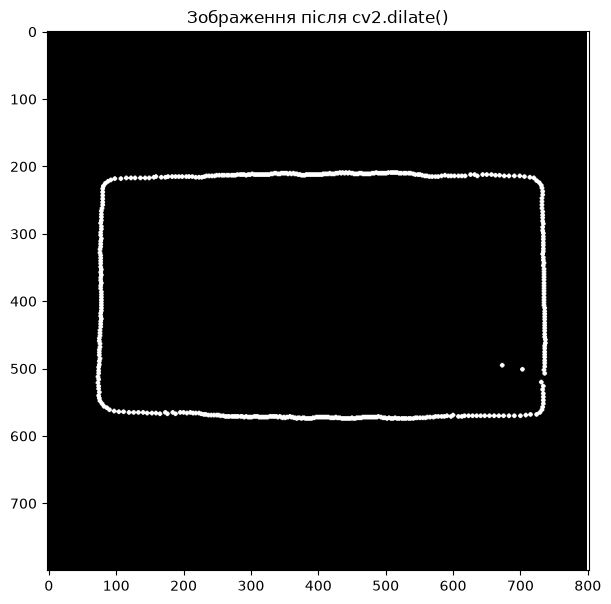

Знайдено відрізків: 87


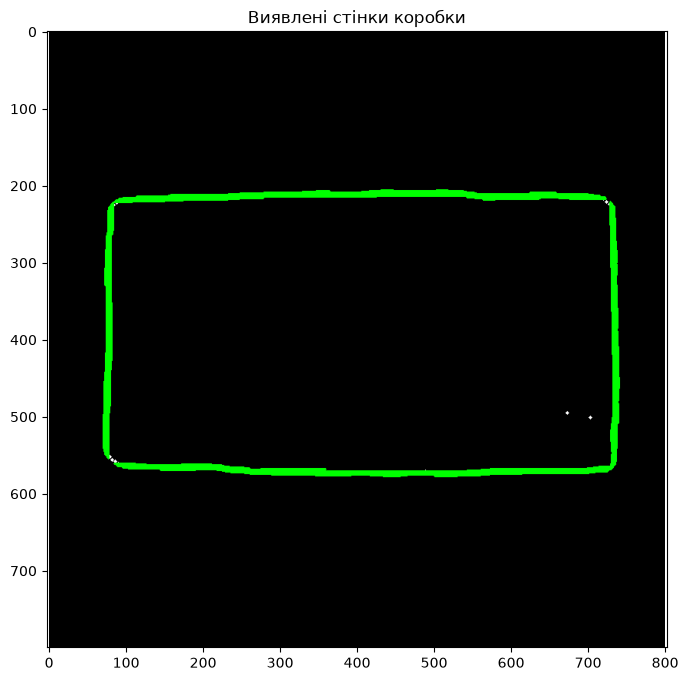

Напрямки знайдених прямих:
Пряма 1: 0.00°
Пряма 2: 0.00°
Пряма 3: 0.00°
Пряма 4: 0.00°
Пряма 5: 88.07°
Пряма 6: 90.00°
Пряма 7: 90.00°
Пряма 8: 0.00°
Пряма 9: 89.14°
Пряма 10: 0.00°
Пряма 11: 0.00°
Пряма 12: 0.00°
Пряма 13: 0.00°
Пряма 14: 0.00°
Пряма 15: 0.00°
Пряма 16: 0.00°
Пряма 17: 0.00°
Пряма 18: 0.00°
Пряма 19: 90.00°
Пряма 20: 90.00°
Пряма 21: 90.00°
Пряма 22: 90.00°
Пряма 23: 0.00°
Пряма 24: 0.00°
Пряма 25: 0.00°
Пряма 26: 90.00°
Пряма 27: 88.99°
Пряма 28: 0.00°
Пряма 29: 0.00°
Пряма 30: 90.00°
Пряма 31: 0.00°
Пряма 32: 90.00°
Пряма 33: 0.00°
Пряма 34: 0.00°
Пряма 35: 0.00°
Пряма 36: 0.00°
Пряма 37: 0.00°
Пряма 38: 179.14°
Пряма 39: 90.00°
Пряма 40: 88.05°
Пряма 41: 0.00°
Пряма 42: 0.00°
Пряма 43: 179.49°
Пряма 44: 90.00°
Пряма 45: 88.07°
Пряма 46: 0.00°
Пряма 47: 179.36°
Пряма 48: 0.00°
Пряма 49: 94.55°
Пряма 50: 0.00°
Пряма 51: 0.00°
Пряма 52: 89.13°
Пряма 53: 0.51°
Пряма 54: 88.53°
Пряма 55: 90.00°
Пряма 56: 90.00°
Пряма 57: 93.69°
Пряма 58: 0.00°
Пряма 59: 179.03°
Пряма 60

In [13]:
from pathlib import Path
import pandas as pd
import numpy as np
import cv2
import matplotlib.pyplot as plt

print(list(Path('data').glob("*.csv")))

data = pd.read_csv(Path('data') / "scan_20261106_103616.csv")

data = data[data["scan"] == 0].copy()

data = data[data["dist_mm"].between(50, 8000)]

print("Кількість точок:", len(data))
data.head()

SIZE = 800
PX = 1000 

center = SIZE // 2

image = np.zeros((SIZE, SIZE), dtype=np.uint8)

angles = np.radians(data["angle_deg"].to_numpy())
distances = data["dist_mm"].to_numpy() / 1000.0

x = distances * np.sin(angles)
y = distances * np.cos(angles)

px = (center + x * PX).astype(int)
py = (center - y * PX).astype(int)

for point_x, point_y in zip(px, py):
    if 0 <= point_x < SIZE and 0 <= point_y < SIZE:
        cv2.circle(image, (point_x, point_y), 2, 255, -1)

plt.figure(figsize=(7, 7))
plt.imshow(image, cmap="gray")
plt.title("Точки LiDAR — порожня коробка")
plt.axis("equal")
plt.show()

kernel = np.ones((3, 3), dtype=np.uint8)

dilated = cv2.dilate(image, kernel, iterations=1)

plt.figure(figsize=(7, 7))
plt.imshow(dilated, cmap="gray")
plt.title("Зображення після cv2.dilate()")
plt.axis("equal")
plt.show()

THRESHOLD = 15
MIN_LINE_LENGTH = 15
MAX_LINE_GAP = 20

lines = cv2.HoughLinesP(
    dilated,
    rho=1,
    theta=np.pi / 180,
    threshold=THRESHOLD,
    minLineLength=MIN_LINE_LENGTH,
    maxLineGap=MAX_LINE_GAP
)

result = cv2.cvtColor(image, cv2.COLOR_GRAY2BGR)

if lines is not None:
    print("Знайдено відрізків:", len(lines))

    for line in lines:
        x1, y1, x2, y2 = line[0]

        cv2.line(
            result,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            2
        )
else:
    print("Прямих не знайдено. Спробуй змінити параметри.")

plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Виявлені стінки коробки")
plt.axis("equal")
plt.show()

if lines is not None and len(lines) >= 2:
    line_angles = []

    for line in lines:
        x1, y1, x2, y2 = line[0]

        angle = np.degrees(
            np.arctan2(y2 - y1, x2 - x1)
        )

        angle = angle % 180

        line_angles.append(angle)

    print("Напрямки знайдених прямих:")

    for i, angle in enumerate(line_angles):
        print(f"Пряма {i + 1}: {angle:.2f}°")

    best_difference = float("inf")
    best_pair = None

    for i in range(len(line_angles)):
        for j in range(i + 1, len(line_angles)):
            difference = abs(line_angles[i] - line_angles[j])
            angle_between = min(difference, 180 - difference)

            error = abs(90 - angle_between)

            if error < best_difference:
                best_difference = error
                best_pair = (i, j, angle_between)

    if best_pair is not None:
        i, j, angle_between = best_pair

        print(
            f"\nКут між прямими {i + 1} і {j + 1}: "
            f"{angle_between:.2f}°"
        )


## Етап 4

Кількість обертів з предметами: 20
Загальна кількість точок: 10080

Відстань між сусідніми точками:
r = 0.1 м: s = 0.13 см
r = 0.2 м: s = 0.25 см
r = 0.3 м: s = 0.38 см

Порівняння параметрів eps:


,"eps, м",Кількість кластерів,Кількість предметів,Кількість кластерів стін,Шумових точок
0,0.005,9.0,2.0,7.0,60.25
1,0.010,4.0,2.0,2.0,9.75
2,0.015,4.0,2.0,2.0,6.50
3,0.020,4.0,2.0,2.0,5.00



Обране eps: 0.01 м
Знайдено кластерів: 4
Виявлено предметів: 2
Кластерів стін: 2
Шумових точок: 9


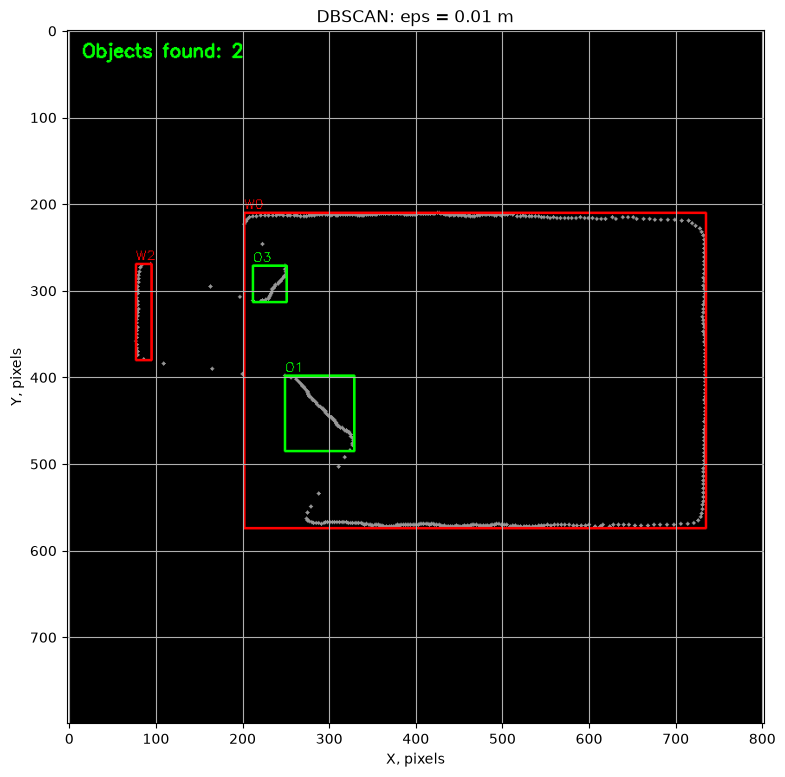


Результати для всіх обертів:


,Оберт,Кількість кластерів,Кількість предметів,Кількість кластерів стін,Шумових точок
0,0,4,2,2,9
1,1,4,2,2,9
2,2,4,2,2,11
3,3,4,2,2,9
4,4,4,2,2,10
5,5,4,2,2,10
6,6,4,2,2,10
7,7,4,2,2,10
8,8,4,2,2,11
9,9,4,2,2,9


In [14]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

from sklearn.cluster import DBSCAN
from scipy.spatial import cKDTree
from IPython.display import display

FILE = Path('data') / "scan_20261107_172450.csv"
EMPTY_FILE = Path('data') / "scan_20261106_103616.csv"

EPS_VALUES = [0.005, 0.01, 0.015, 0.02]
EPS = 0.01
MIN_SAMPLES = 3

WALL_TOLERANCE = 0.015
WALL_MATCH_RATIO = 0.5

SIZE = 800
PX = 1000
CENTER = SIZE // 2

STEP_DEG = 0.72

data = pd.read_csv(FILE)
empty_data = pd.read_csv(EMPTY_FILE)

data = data[data["dist_mm"].between(50, 8000)]
empty_data = empty_data[empty_data["dist_mm"].between(50, 8000)]

print("Кількість обертів з предметами:", data["scan"].nunique())
print("Загальна кількість точок:", len(data))

print("\nВідстань між сусідніми точками:")

for r in [0.1, 0.2, 0.3]:
    s = r * np.radians(STEP_DEG)
    print(f"r = {r:.1f} м: s = {s * 100:.2f} см")

def convert_to_points(scan_data):
    angles = np.radians(scan_data["angle_deg"].to_numpy())
    distances = scan_data["dist_mm"].to_numpy() / 1000.0

    x = distances * np.sin(angles)
    y = distances * np.cos(angles)

    return np.column_stack((x, y))

empty_points = []

for scan_id in sorted(empty_data["scan"].unique()):
    scan_data = empty_data[empty_data["scan"] == scan_id]
    empty_points.append(convert_to_points(scan_data))

empty_points = np.vstack(empty_points)

# Створюємо дерево пошуку найближчих точок стін
wall_tree = cKDTree(empty_points)

def analyze_clusters(points, eps):
    labels = DBSCAN(
        eps=eps,
        min_samples=MIN_SAMPLES
    ).fit_predict(points)

    clusters = sorted(set(labels) - {-1})

    objects_count = 0
    walls_count = 0

    for cluster_id in clusters:
        cluster_points = points[labels == cluster_id]

        # Відстань кожної точки до найближчої точки порожньої коробки
        distances, _ = wall_tree.query(cluster_points)

        wall_ratio = np.mean(distances <= WALL_TOLERANCE)

        if wall_ratio >= WALL_MATCH_RATIO:
            walls_count += 1
        else:
            objects_count += 1

    return labels, len(clusters), objects_count, walls_count

results = []
scan_results = {}

scan_ids = sorted(data["scan"].unique())

for scan_id in scan_ids:
    scan_data = data[data["scan"] == scan_id]
    points = convert_to_points(scan_data)

    for eps in EPS_VALUES:
        labels, clusters_count, objects_count, walls_count = (
            analyze_clusters(points, eps)
        )

        results.append({
            "Оберт": scan_id,
            "eps, м": eps,
            "Кількість кластерів": clusters_count,
            "Кількість предметів": objects_count,
            "Кількість кластерів стін": walls_count,
            "Шумових точок": np.sum(labels == -1)
        })

    if scan_id == scan_ids[0]:
        scan_results["points"] = points

results_df = pd.DataFrame(results)

summary = (
    results_df
    .groupby("eps, м")
    .agg({
        "Кількість кластерів": "mean",
        "Кількість предметів": "mean",
        "Кількість кластерів стін": "mean",
        "Шумових точок": "mean"
    })
    .round(2)
    .reset_index()
)

print("\nПорівняння параметрів eps:")
display(summary)

points = scan_results["points"]

labels, clusters_count, objects_count, walls_count = (
    analyze_clusters(points, EPS)
)

clusters = sorted(set(labels) - {-1})

print(f"\nОбране eps: {EPS} м")
print("Знайдено кластерів:", clusters_count)
print("Виявлено предметів:", objects_count)
print("Кластерів стін:", walls_count)
print("Шумових точок:", np.sum(labels == -1))

image = np.zeros((SIZE, SIZE, 3), dtype=np.uint8)

px = (CENTER + points[:, 0] * PX).astype(int)
py = (CENTER - points[:, 1] * PX).astype(int)

for x_pixel, y_pixel in zip(px, py):
    if 0 <= x_pixel < SIZE and 0 <= y_pixel < SIZE:
        cv2.circle(
            image,
            (x_pixel, y_pixel),
            2,
            (150, 150, 150),
            -1
        )

for cluster_id in clusters:
    cluster_points = points[labels == cluster_id]

    distances, _ = wall_tree.query(cluster_points)
    wall_ratio = np.mean(distances <= WALL_TOLERANCE)

    is_wall = wall_ratio >= WALL_MATCH_RATIO

    cluster_pixels = np.column_stack((
        px[labels == cluster_id],
        py[labels == cluster_id]
    ))

    cluster_pixels = cluster_pixels[
        (cluster_pixels[:, 0] >= 0) &
        (cluster_pixels[:, 0] < SIZE) &
        (cluster_pixels[:, 1] >= 0) &
        (cluster_pixels[:, 1] < SIZE)
    ]

    if len(cluster_pixels) == 0:
        continue

    cluster_pixels = cluster_pixels.reshape(-1, 1, 2)

    x_box, y_box, width, height = cv2.boundingRect(
        cluster_pixels
    )

    if is_wall:
        color = (0, 0, 255)
        label_text = f"W{cluster_id}"
    else:
        color = (0, 255, 0)
        label_text = f"O{cluster_id}"

    cv2.rectangle(
        image,
        (x_box, y_box),
        (x_box + width, y_box + height),
        color,
        2
    )

    cv2.putText(
        image,
        label_text,
        (x_box, max(y_box - 5, 15)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        color,
        1
    )

cv2.putText(
    image,
    f"Objects found: {objects_count}",
    (15, 30),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.7,
    (0, 255, 0),
    2
)

plt.figure(figsize=(9, 9))

plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))

plt.title(f"DBSCAN: eps = {EPS} m")
plt.xlabel("X, pixels")
plt.ylabel("Y, pixels")
plt.axis("equal")
plt.grid()

plt.show()

print("\nРезультати для всіх обертів:")

display(
    results_df[results_df["eps, м"] == EPS][
        [
            "Оберт",
            "Кількість кластерів",
            "Кількість предметів",
            "Кількість кластерів стін",
            "Шумових точок"
        ]
    ].reset_index(drop=True)
)

## Порівняння: DBSCAN і k-means

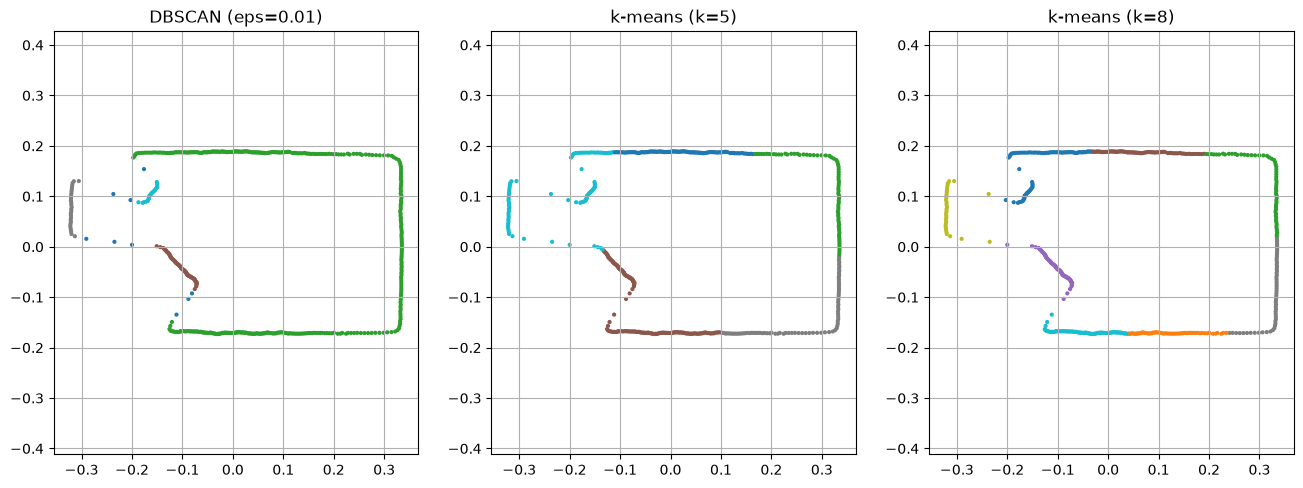

In [11]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN, KMeans

FILE = Path.home() / 'lidar_d500' / 'data' / 'scan_20261107_172450.csv'
df = pd.read_csv(FILE)
df = df[(df['scan'] == 0) & (df['dist_mm'].between(50, 8000))]

angles = np.radians(df['angle_deg'].to_numpy())
distances = df['dist_mm'].to_numpy() / 1000.0
xy = np.column_stack((distances * np.sin(angles), distances * np.cos(angles)))

runs = [
    ('DBSCAN (eps=0.01)', DBSCAN(eps=0.01, min_samples=3).fit_predict(xy)),
    ('k-means (k=5)', KMeans(n_clusters=5, n_init=10, random_state=0).fit_predict(xy)),
    ('k-means (k=8)', KMeans(n_clusters=8, n_init=10, random_state=0).fit_predict(xy))
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
for ax, (title, labels) in zip(axes, runs):
    ax.scatter(xy[:, 0], xy[:, 1], c=labels, s=4, cmap='tab10')
    ax.set_title(title)
    ax.axis('equal')
    ax.grid(True)

plt.show()